# Unwrapping AI — Zero to Transformer
## Step 05: Understanding Overfitting

**Creator:** Nitin K. Sethi  
**Learning format:** Understand → Implement → Compare → Interpret  
**Environment:** Google Colab | Python | NumPy | Pandas | Matplotlib | scikit-learn

### Learning objectives
By the end of this notebook, you will be able to:
1. Explain underfitting, a useful fit, and overfitting.
2. Compare training and validation error as model complexity increases.
3. Select a model using validation performance rather than training error alone.
4. Keep a test set separate for a final, unbiased evaluation.

**Roadmap status:** Step 05 of 12 — Overfitting. Steps 01–04 are treated as completed based on your latest confirmation.

## 1. The concept

A model **underfits** when it is too simple to capture the pattern in the data.

A model **overfits** when it learns not only the underlying pattern but also random noise or peculiarities in the training sample. It can look excellent on training data and perform poorly on unseen data.

The warning sign is a widening gap:
- Training error keeps falling.
- Validation error stops improving or starts increasing.

For this exercise, model complexity will be controlled by the degree of a polynomial regression model.

### Connect to Step 02: Mean Squared Error

We will use mean squared error (MSE) to compare model predictions:

\[
\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
\]

A lower MSE means smaller average squared prediction errors **on that particular dataset**. A very low training MSE does not guarantee good performance on new data.

In [1]:
# 2. Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Create a small, reproducible dataset

The hidden pattern is curved, while the observed values contain random noise. This lets us see what happens when a model becomes increasingly flexible.

This is a teaching dataset, not real customer or banking data.

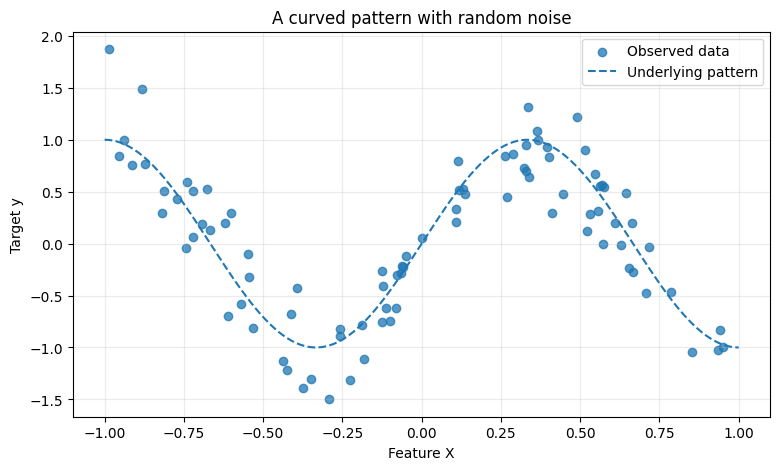

Total observations: 90


In [2]:
# 3. Generate the dataset
NOISE_LEVEL = 0.30
rng = np.random.default_rng(42)

X = rng.uniform(-1, 1, 90).reshape(-1, 1)
y = np.sin(1.5 * np.pi * X[:, 0]) + rng.normal(0, NOISE_LEVEL, 90)

x_curve = np.linspace(-1, 1, 400).reshape(-1, 1)
y_true_curve = np.sin(1.5 * np.pi * x_curve[:, 0])

plt.figure(figsize=(9, 5))
plt.scatter(X[:, 0], y, alpha=0.75, label="Observed data")
plt.plot(x_curve[:, 0], y_true_curve, linestyle="--", label="Underlying pattern")
plt.title("A curved pattern with random noise")
plt.xlabel("Feature X")
plt.ylabel("Target y")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print(f"Total observations: {len(X)}")

## 3. Create training, validation and test sets

We will use:
- **60% training:** fit the model.
- **20% validation:** compare model complexity and choose a candidate.
- **20% test:** evaluate the selected model once at the end.

The test set is kept out of model selection. This is important: repeatedly choosing models based on test results would leak information from the test set into development.

In [3]:
# 4. Split the data: 60% train, 20% validation, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=RANDOM_STATE
)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Rows": [len(X_train), len(X_validation), len(X_test)],
    "Share": [
        len(X_train) / len(X),
        len(X_validation) / len(X),
        len(X_test) / len(X)
    ]
})

display(split_summary)
assert len(X_train) + len(X_validation) + len(X_test) == len(X)
assert len(X_train) == 54 and len(X_validation) == 18 and len(X_test) == 18

,Dataset,Rows,Share
0,Training,54,0.6
1,Validation,18,0.2
2,Test,18,0.2


## 4. Train models with different complexity

We will test polynomial degrees 1, 3, 5, 8 and 10.

- Degree 1 is a straight line and may underfit the curved pattern.
- Higher degrees can represent more complex shapes.
- Excessive flexibility can fit noise and reduce generalisation.

The scaler is placed inside a scikit-learn pipeline so each model's transformations are fitted using training data only.

In [4]:
# 5. Fit each model and compare training vs validation MSE
degrees = [1, 3, 5, 8, 10]
models = {}
results = []

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
    model.fit(X_train, y_train)
    models[degree] = model

    train_predictions = model.predict(X_train)
    validation_predictions = model.predict(X_validation)

    results.append({
        "Polynomial degree": degree,
        "Training MSE": mean_squared_error(y_train, train_predictions),
        "Validation MSE": mean_squared_error(y_validation, validation_predictions),
        "Training R²": r2_score(y_train, train_predictions),
        "Validation R²": r2_score(y_validation, validation_predictions)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Polynomial degree,Training MSE,Validation MSE,Training R²,Validation R²
0,1,0.5160,0.7049,0.0000,-0.2133
1,3,0.1679,0.2973,0.6746,0.4884
2,5,0.1038,0.1557,0.7988,0.7320
3,8,0.0767,0.1536,0.8514,0.7357
4,10,0.0724,0.2568,0.8597,0.5579


## 5. Visualise the error gap

Look for the point where training error continues to decrease but validation error starts increasing. That is the practical warning sign of overfitting.

The validation set helps us choose complexity. We do not choose the model simply because it has the smallest training MSE.

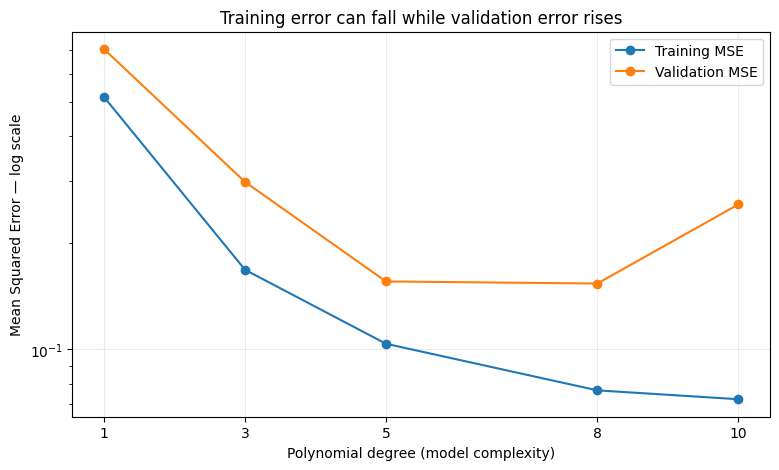

In [5]:
# 6. Plot training and validation MSE
plt.figure(figsize=(9, 5))
plt.plot(results_df["Polynomial degree"], results_df["Training MSE"], marker="o", label="Training MSE")
plt.plot(results_df["Polynomial degree"], results_df["Validation MSE"], marker="o", label="Validation MSE")
plt.yscale("log")
plt.xticks(degrees)
plt.xlabel("Polynomial degree (model complexity)")
plt.ylabel("Mean Squared Error — log scale")
plt.title("Training error can fall while validation error rises")
plt.legend()
plt.grid(alpha=0.25)
plt.savefig(OUTPUT_DIR / "step05_train_validation_mse.png", dpi=160, bbox_inches="tight")
plt.show()

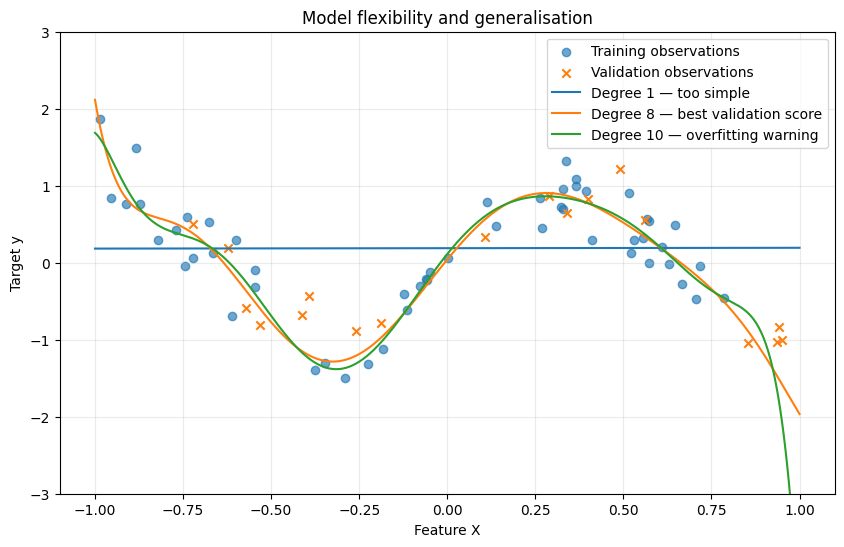

In [6]:
# 7. Compare the fitted curves for an underfit, selected and overfit model
plt.figure(figsize=(10, 6))
plt.scatter(X_train[:, 0], y_train, alpha=0.65, label="Training observations")
plt.scatter(X_validation[:, 0], y_validation, marker="x", label="Validation observations")

for degree, label in [(1, "Degree 1 — too simple"), (8, "Degree 8 — best validation score"), (10, "Degree 10 — overfitting warning")]:
    plt.plot(
        x_curve[:, 0],
        models[degree].predict(x_curve),
        label=label
    )

plt.ylim(-3, 3)  # Keeps the comparison readable if a flexible model makes extreme predictions.
plt.xlabel("Feature X")
plt.ylabel("Target y")
plt.title("Model flexibility and generalisation")
plt.legend()
plt.grid(alpha=0.25)
plt.savefig(OUTPUT_DIR / "step05_model_complexity.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Select using validation, then test once

We choose the degree with the lowest validation MSE. Only after that choice do we evaluate the selected model on the untouched test set.

The exact scores can vary if you change the random seed, sample size, noise level or degrees.

In [7]:
# 8. Choose the model using validation MSE
best_row = results_df.loc[results_df["Validation MSE"].idxmin()]
best_degree = int(best_row["Polynomial degree"])
best_model = models[best_degree]

test_predictions = best_model.predict(X_test)
final_test_mse = mean_squared_error(y_test, test_predictions)
final_test_r2 = r2_score(y_test, test_predictions)

print(f"Selected polynomial degree: {best_degree}")
print(f"Validation MSE: {best_row['Validation MSE']:.4f}")
print(f"Final test MSE: {final_test_mse:.4f}")
print(f"Final test R²: {final_test_r2:.4f}")

assert best_degree == 8
assert np.isfinite(final_test_mse)
assert np.isfinite(final_test_r2)

Selected polynomial degree: 8
Validation MSE: 0.1536
Final test MSE: 0.0460
Final test R²: 0.8906


## 7. Interpret the result

Use your own output table and charts to answer:

1. Which model has the lowest training MSE?
2. Which model has the lowest validation MSE?
3. What happens to validation MSE when complexity increases beyond the best-performing degree?
4. Why would selecting only by training MSE be misleading?
5. Why did we keep the test set untouched until the final evaluation?

### Key takeaway

**A model that memorises its training data is not necessarily a model that generalises.** The goal is not to minimise training error at any cost; it is to learn patterns that remain useful on unseen data.

### What can reduce overfitting?
- Collect more representative data.
- Reduce unnecessary model complexity.
- Use regularization.
- Use cross-validation for more reliable model selection.

These lead directly into later roadmap steps, especially **Step 06: Regularization** and **Step 07: Cross-Validation**.

In [8]:
print("To change the noise level, edit NOISE_LEVEL in the dataset-generation cell, then rerun from that cell onward.")

To change the noise level, edit NOISE_LEVEL in the dataset-generation cell, then rerun from that cell onward.


In [9]:
# 10. Confirm the visual assets were saved
for asset_path in sorted(OUTPUT_DIR.glob("*.png")):
    print(asset_path, "—", f"{asset_path.stat().st_size:,} bytes")

assert len(list(OUTPUT_DIR.glob("*.png"))) == 2

outputs/step05_model_complexity.png — 125,027 bytes
outputs/step05_train_validation_mse.png — 74,078 bytes


## 8. Completion checklist

Mark Step 05 complete only after you have run all cells in Google Colab and checked:

- [ ] The dataset contains 90 observations.
- [ ] The split is 54 training, 18 validation and 18 test rows.
- [ ] The results table contains five model degrees.
- [ ] The training-vs-validation MSE chart is displayed.
- [ ] The degree-1, degree-8 and degree-10 curves are displayed.
- [ ] The selected model is degree 8 with this fixed random seed.
- [ ] Final test metrics are printed and finite.
- [ ] You can explain why degree 10 has lower training error but worse validation error than degree 8.

**Expected reference output with the supplied seed and settings:** degree 8 is selected; validation MSE is approximately 0.1536; final test MSE is approximately 0.0460; final test R² is approximately 0.8906. Small differences can occur across library versions.

## GitHub update

Repository: `MeNitinsethi/Zero-to-transformer`

1. In Colab, select **Runtime → Run all** and wait for every cell to finish.
2. Select **File → Save a copy in GitHub** (or download the `.ipynb` and upload it through the repository's web interface).
3. Use this filename: `Unwrapping_AI_Zero_to_Transformer_Step_05_Overfitting.ipynb`
4. Suggested commit message: `Add Step 05 - Overfitting experiment`
5. Update the README roadmap status for Step 05 only after the notebook is run and verified.
6. Keep the notebook outputs and plots so the repository shows the experiment results.

**Do not mark Step 05 complete or claim it is published until the Colab run and GitHub commit are confirmed.**

## LinkedIn draft — publish only after you run the notebook

I tested how model complexity affects generalisation in a small machine-learning experiment.

The key observation: as polynomial degree increased, training error kept falling. But validation error did not keep improving.

That is the overfitting problem.

A model can become better at fitting the examples it has already seen while becoming worse at predicting unseen examples.

In this experiment, I compared polynomial degrees using a separate validation set, selected the model with the lowest validation MSE, and kept the test set untouched until the final evaluation.

My biggest takeaway:

**The model with the lowest training error is not automatically the best model.**

This is Step 05 in my Unwrapping AI — Zero to Transformer learning journey.

Next: Regularization — how can we control model complexity?

#UnwrappingAI #MachineLearning #Overfitting #ModelEvaluation #DataScience

*Before publishing, replace the generic description with the actual metrics and a screenshot from your completed Colab run. Do not publish this as a completed experiment until you have run it.*